In [1]:
import numpy as np
import matplotlib.pylab as plt
from HankelDMD_Predictor import HankelDMD_Predictor as HDMDP
from tqdm.auto import tqdm
plt.rcParams['figure.dpi']=400

Let us denote our data matrix as $X$, its corresponding pseudohankel matrix as $H$, and the right singular vectors of $H$ scaled by their singular values as $W$. Let's denote the corresponding matrices shifted by a fixed number of time points with the same letter and an apostrophe, so e.g. $X'$ is the shifted data matrix. Then at a high level, the HankelDMD pipeline is as follows:

$$X\xrightarrow{\text{Hankel}}H\xrightarrow{\text{SVD}}W\xrightarrow{A}W'\xrightarrow{\text{Invert SVD}}H'\xrightarrow{\text{Dehankel}}X'.$$

Currently, there is an issue predicting $X'$. This notebook is for troubleshooting where the failure in the pipeline is.

First let's note that $X$ and $H$ contain the exact same information, and so either one can be computed from the other losslessly. Therefore the issue must exist in this inner section:

$$H\xrightarrow{\text{SVD}}W\xrightarrow{A}W'\xrightarrow{\text{Invert SVD}}H'.$$

Furthermore, although the computation of the SVD of $H$ is done with numerical methods, we can choose the precision to be high enough to not be of concern. Therefore the issue must lie in one or both of these two steps:

$$W\xrightarrow{A}W'\xrightarrow{\text{Invert SVD}}H'.$$

There are then three hypotheses, with different predictions:

### Hypothesis 1: We cannot compute $W'$ with $A$ and $W$, but we can compute $H'$ from $W'$ by inverting the SVD.
### Hypothesis 2: We can compute $W'$ with $A$ and $W$, but we cannot compute $H'$ from $W'$ by inverting the SVD.
### Hypothesis 3: We can neither compute $W'$ with $A$ and $W$ nor can we compute $H'$ from $W'$ by inverting the SVD.

All of our predictions will require us to know what $W'$ and $H'$ actually are. Thankfully we can compute these by inverting the last three steps of the pipeline:

$$X'\xrightarrow{\text{Hankel}}H'\xrightarrow{\text{SVD}}W'.$$

For the SVD here we multiply by the $U^T$ found from the SVD on $H$. Between the SVDs on $H$ and $H'$, $U$ should be unchanged up to sign differences that we want to avoid for calculating RSEs.

### **Prediction of Hypothesis 1**
The RSE of the predicted $W'$ will be high. However, given the true $W'$, the RSE of the computed $H'$ will be low.

### **Prediction of Hypothesis 2**
The RSE of the predicted $W'$ will be low. But given the true $W'$, the RSE of the computed $H'$ will be high.

### **Prediction of Hypothesis 3**
The RSE of the predicted $W'$ will be high. Furthermore, given the true $W'$, the RSE of the computed $H'$ will be high as well.

# **Testing Hypotheses**

In [2]:
# Load data
WF_data = np.load('../Mouse Data/svdTemporalComponents_corr.npy')[:,:50]
WF_data_smaller = WF_data / np.linalg.norm(WF_data)
# Define RSE metric
RSE = lambda X,Y,Y_train: np.mean((Y-np.real(X))**2)/np.mean((Y-np.mean(Y_train,axis=1,keepdims=True))**2)

In [3]:
RSEs_W = []
RSEs_H_from_true = []
RSEs_H_from_pred = []
for i in tqdm(range(100)):
    # True data
    X = WF_data[i*500:(i+1)*500]
    Xp = WF_data[i*500:(i+1)*500+35]
    # Fit HankelDMD
    hdmdp = HDMDP(400,7)
    hdmdp.fit(X)
    # Predict new columns of W'
    Wp_prediction = hdmdp.predict(35,False,False)
    # Prediction new columns of H' from predicted W'
    Hp_prediction_from_pred = hdmdp._U@Wp_prediction
    # Compute true H'
    Hp = hdmdp._hankel_maker(Xp,136)
    # Compute true W'
    Wp = hdmdp._U.T@Hp
    # Predict new columns of H' from true W'
    Hp_prediction_from_true = hdmdp._U@Wp[:,101:]
    # Assess prediction of W' from W
    RSEs_W.append(RSE(Wp_prediction,Wp[:,101:],Wp[:,101,None]))
    # Assess prediction of H' from true W'
    RSEs_H_from_true.append(RSE(Hp_prediction_from_true[hdmdp._d-1::hdmdp._d],Hp[hdmdp._d-1::hdmdp._d,101:],Hp[hdmdp._d-1::hdmdp._d,101,None]))
    # Assess prediction from H' from predicted W'
    RSEs_H_from_pred.append(RSE(Hp_prediction_from_pred[hdmdp._d-1::hdmdp._d],Hp[hdmdp._d-1::hdmdp._d,101:],Hp[hdmdp._d-1::hdmdp._d,101,None]))

  0%|          | 0/100 [00:00<?, ?it/s]

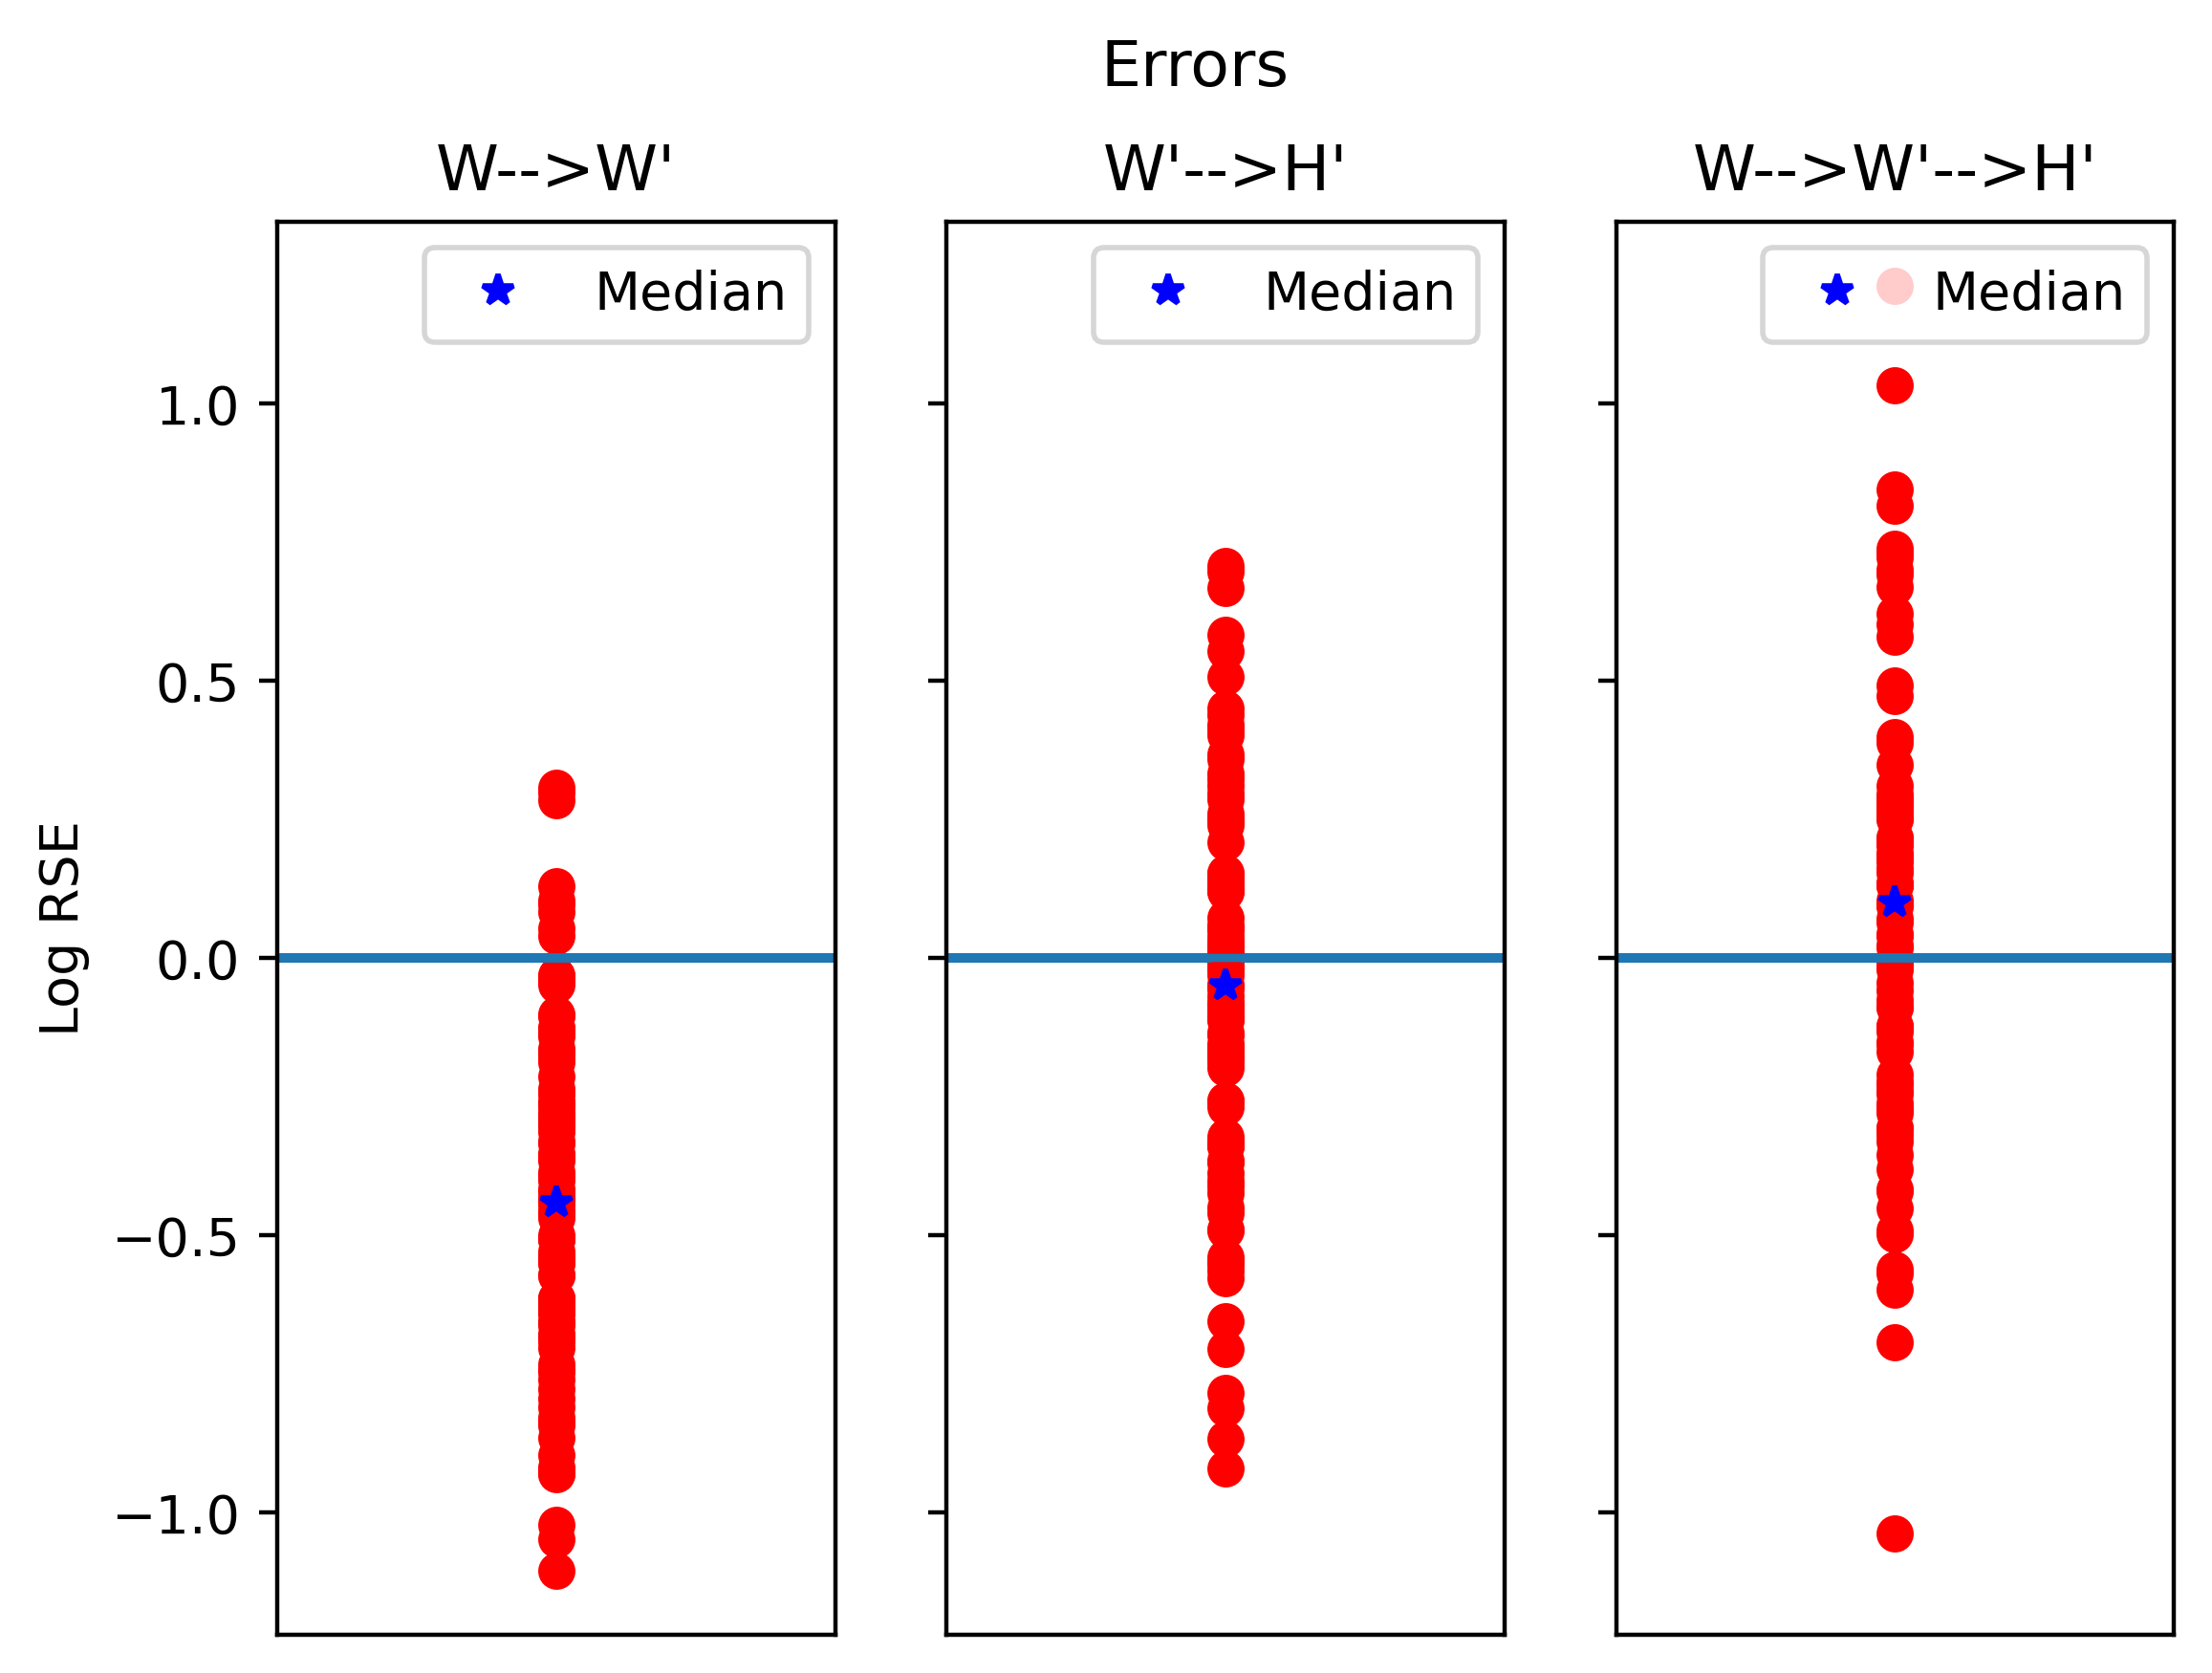

In [4]:
fig,ax = plt.subplots(1,3,sharex=True,sharey=True)
for rse_w,rse_ht,rse_hp in zip(RSEs_W,RSEs_H_from_true,RSEs_H_from_pred):
    ax[0].plot(0,np.log10(rse_w),'ro')
    ax[0].axhline(0)
    ax[0].set_xticks([])
    ax[0].set_ylabel("Log RSE")
    ax[0].set_title("W-->W'")
    ax[1].plot(0,np.log10(rse_ht),'ro')
    ax[1].axhline(0)
    ax[1].set_title("W'-->H'")
    ax[2].plot(0,np.log10(rse_hp),'ro')
    ax[2].axhline(0)
    ax[2].set_title("W-->W'-->H'")
fig.suptitle("Errors")
ax[0].plot(0,np.log10(np.median(RSEs_W)),'b*',label="Median")
ax[1].plot(0,np.log10(np.median(RSEs_H_from_true)),'b*',label="Median")
ax[2].plot(0,np.log10(np.median(RSEs_H_from_pred)),'b*',label="Median")
ax[0].legend()
ax[1].legend()
ax[2].legend()

**This strongly supports Hypothesis 2**.

However, which hypothesis is true may depend on the hyperparameters of the model. We would expect the $H'$ prediction error to decrease as the rank of the SVD is increased. Let's try that next.

In [12]:
RSEs_W = []
RSEs_H_from_true = []
RSEs_H_from_pred = []
for i in tqdm(range(100)):
    # True data
    X = WF_data[i*500:(i+1)*500]
    Xp = WF_data[i*500:(i+1)*500+35]
    # Fit HankelDMD
    hdmdp = HDMDP(400,100)
    hdmdp.fit(X)
    # Predict new columns of W'
    Wp_prediction = hdmdp.predict(35,False,False)
    # Prediction new columns of H' from predicted W'
    Hp_prediction_from_pred = hdmdp._U@Wp_prediction
    # Compute true H'
    Hp = hdmdp._hankel_maker(Xp,136)
    # Compute true W'
    Wp = hdmdp._U.T@Hp
    # Predict new columns of H' from true W'
    Hp_prediction_from_true = hdmdp._U@Wp[:,101:]
    # Assess prediction of W' from W
    RSEs_W.append(RSE(Wp_prediction,Wp[:,101:],Wp[:,101,None]))
    # Assess prediction of H' from true W'
    RSEs_H_from_true.append(RSE(Hp_prediction_from_true[hdmdp._d-1::hdmdp._d],Hp[hdmdp._d-1::hdmdp._d,101:],Hp[hdmdp._d-1::hdmdp._d,101,None]))
    # Assess prediction from H' from predicted W'
    RSEs_H_from_pred.append(RSE(Hp_prediction_from_pred[hdmdp._d-1::hdmdp._d],Hp[hdmdp._d-1::hdmdp._d,101:],Hp[hdmdp._d-1::hdmdp._d,101,None]))

  0%|          | 0/100 [00:00<?, ?it/s]

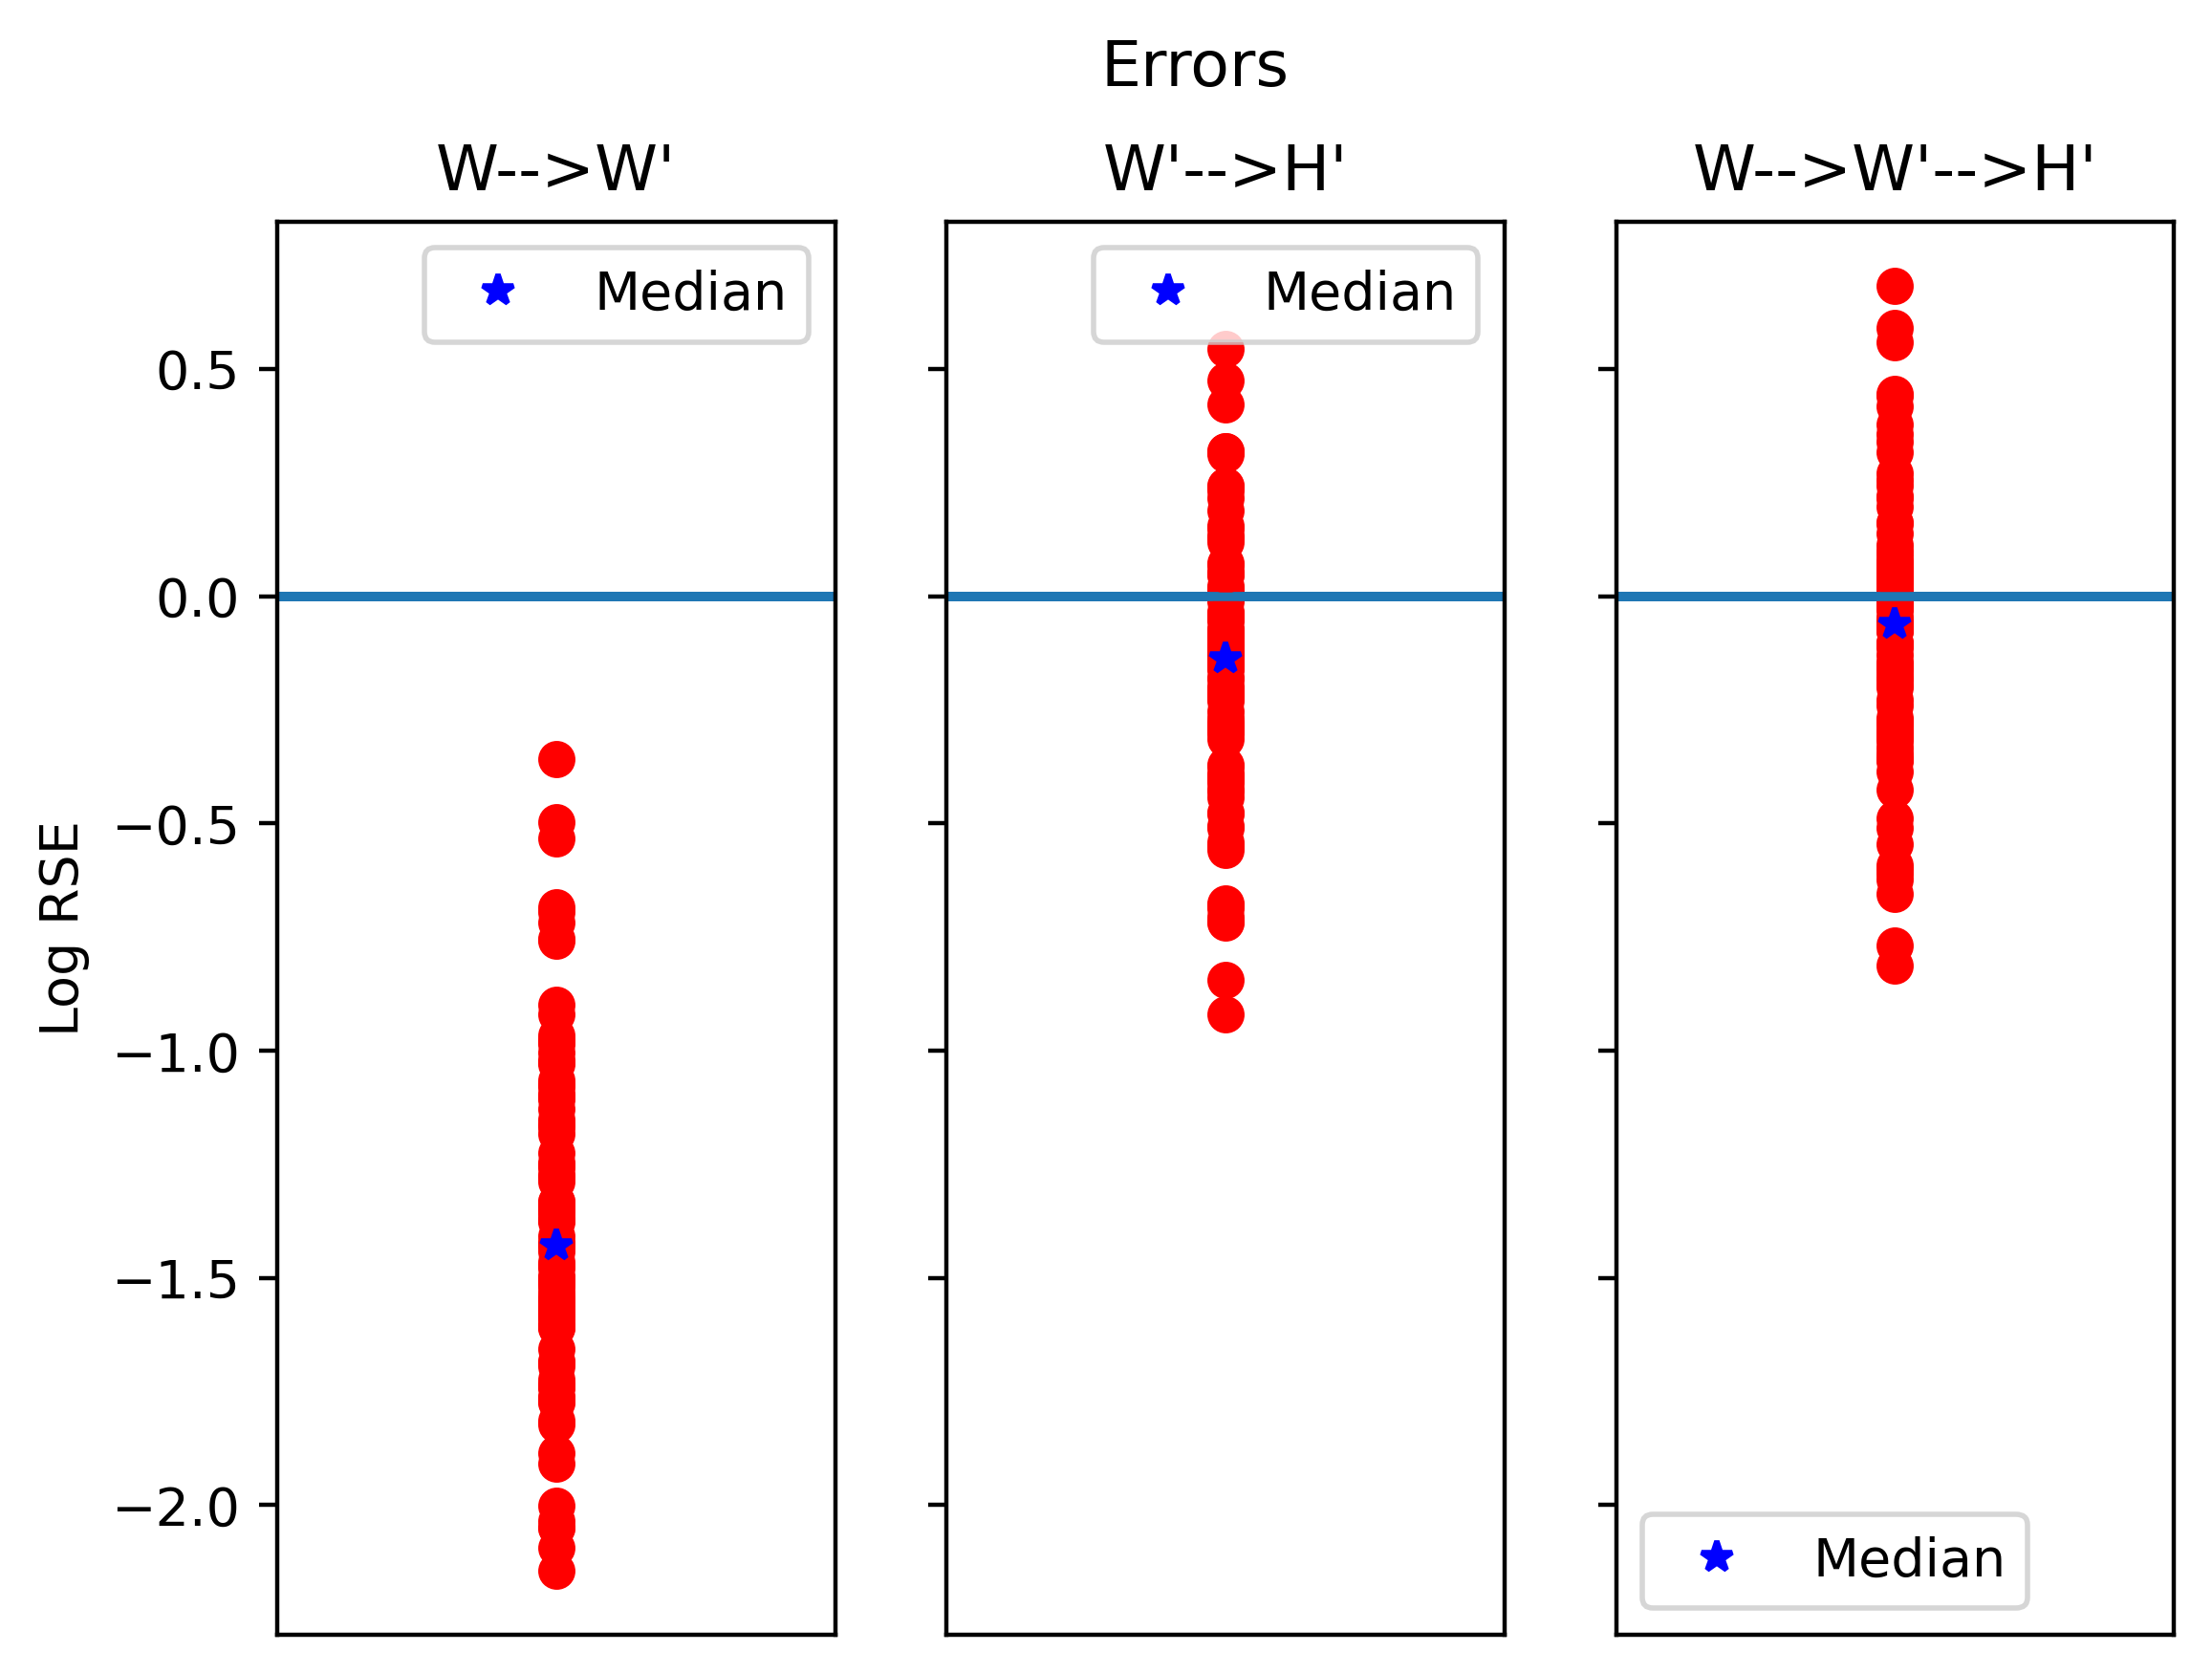

In [13]:
fig,ax = plt.subplots(1,3,sharex=True,sharey=True)
for rse_w,rse_ht,rse_hp in zip(RSEs_W,RSEs_H_from_true,RSEs_H_from_pred):
    ax[0].plot(0,np.log10(rse_w),'ro')
    ax[0].axhline(0)
    ax[0].set_xticks([])
    ax[0].set_ylabel("Log RSE")
    ax[0].set_title("W-->W'")
    ax[1].plot(0,np.log10(rse_ht),'ro')
    ax[1].axhline(0)
    ax[1].set_title("W'-->H'")
    ax[2].plot(0,np.log10(rse_hp),'ro')
    ax[2].axhline(0)
    ax[2].set_title("W-->W'-->H'")
fig.suptitle("Errors")
ax[0].plot(0,np.log10(np.median(RSEs_W)),'b*',label="Median")
ax[1].plot(0,np.log10(np.median(RSEs_H_from_true)),'b*',label="Median")
ax[2].plot(0,np.log10(np.median(RSEs_H_from_pred)),'b*',label="Median")
ax[0].legend()
ax[1].legend()
ax[2].legend()

**Even with the maximum possible rank with this number of time delays, inverting the SVD still appears to be the bottleneck, supporting Hypothesis 2.**

Next we can try with fewer time delays, which will let us increase the rank further.

In [3]:
import warnings
warnings.filterwarnings('ignore')
RSEs_W = []
RSEs_H_from_true = []
RSEs_H_from_pred = []
for i in tqdm(range(100)):
    # True data
    X = WF_data[i*500:(i+1)*500]
    Xp = WF_data[i*500:(i+1)*500+35]
    # Fit HankelDMD
    hdmdp = HDMDP(100,400)
    hdmdp.fit(X)
    # Predict new columns of W'
    Wp_prediction = hdmdp.predict(35,False,False)
    # Prediction new columns of H' from predicted W'
    Hp_prediction_from_pred = hdmdp._U@Wp_prediction
    # Compute true H'
    Hp = hdmdp._hankel_maker(Xp,hdmdp._window_length+35)
    # Compute true W'
    Wp = hdmdp._U.T@Hp
    # Predict new columns of H' from true W'
    Hp_prediction_from_true = hdmdp._U@Wp[:,hdmdp._window_length:]
    # Assess prediction of W' from W
    RSEs_W.append(RSE(Wp_prediction,Wp[:,hdmdp._window_length:],Wp[:,hdmdp._window_length,None]))
    # Assess prediction of H' from true W'
    RSEs_H_from_true.append(RSE(Hp_prediction_from_true[hdmdp._d-1::hdmdp._d],Hp[hdmdp._d-1::hdmdp._d,hdmdp._window_length:],Hp[hdmdp._d-1::hdmdp._d,hdmdp._window_length,None]))
    # Assess prediction of H' from predicted W'
    RSEs_H_from_pred.append(RSE(Hp_prediction_from_pred[hdmdp._d-1::hdmdp._d],Hp[hdmdp._d-1::hdmdp._d,hdmdp._window_length:],Hp[hdmdp._d-1::hdmdp._d,hdmdp._window_length,None]))

  0%|          | 0/100 [00:00<?, ?it/s]

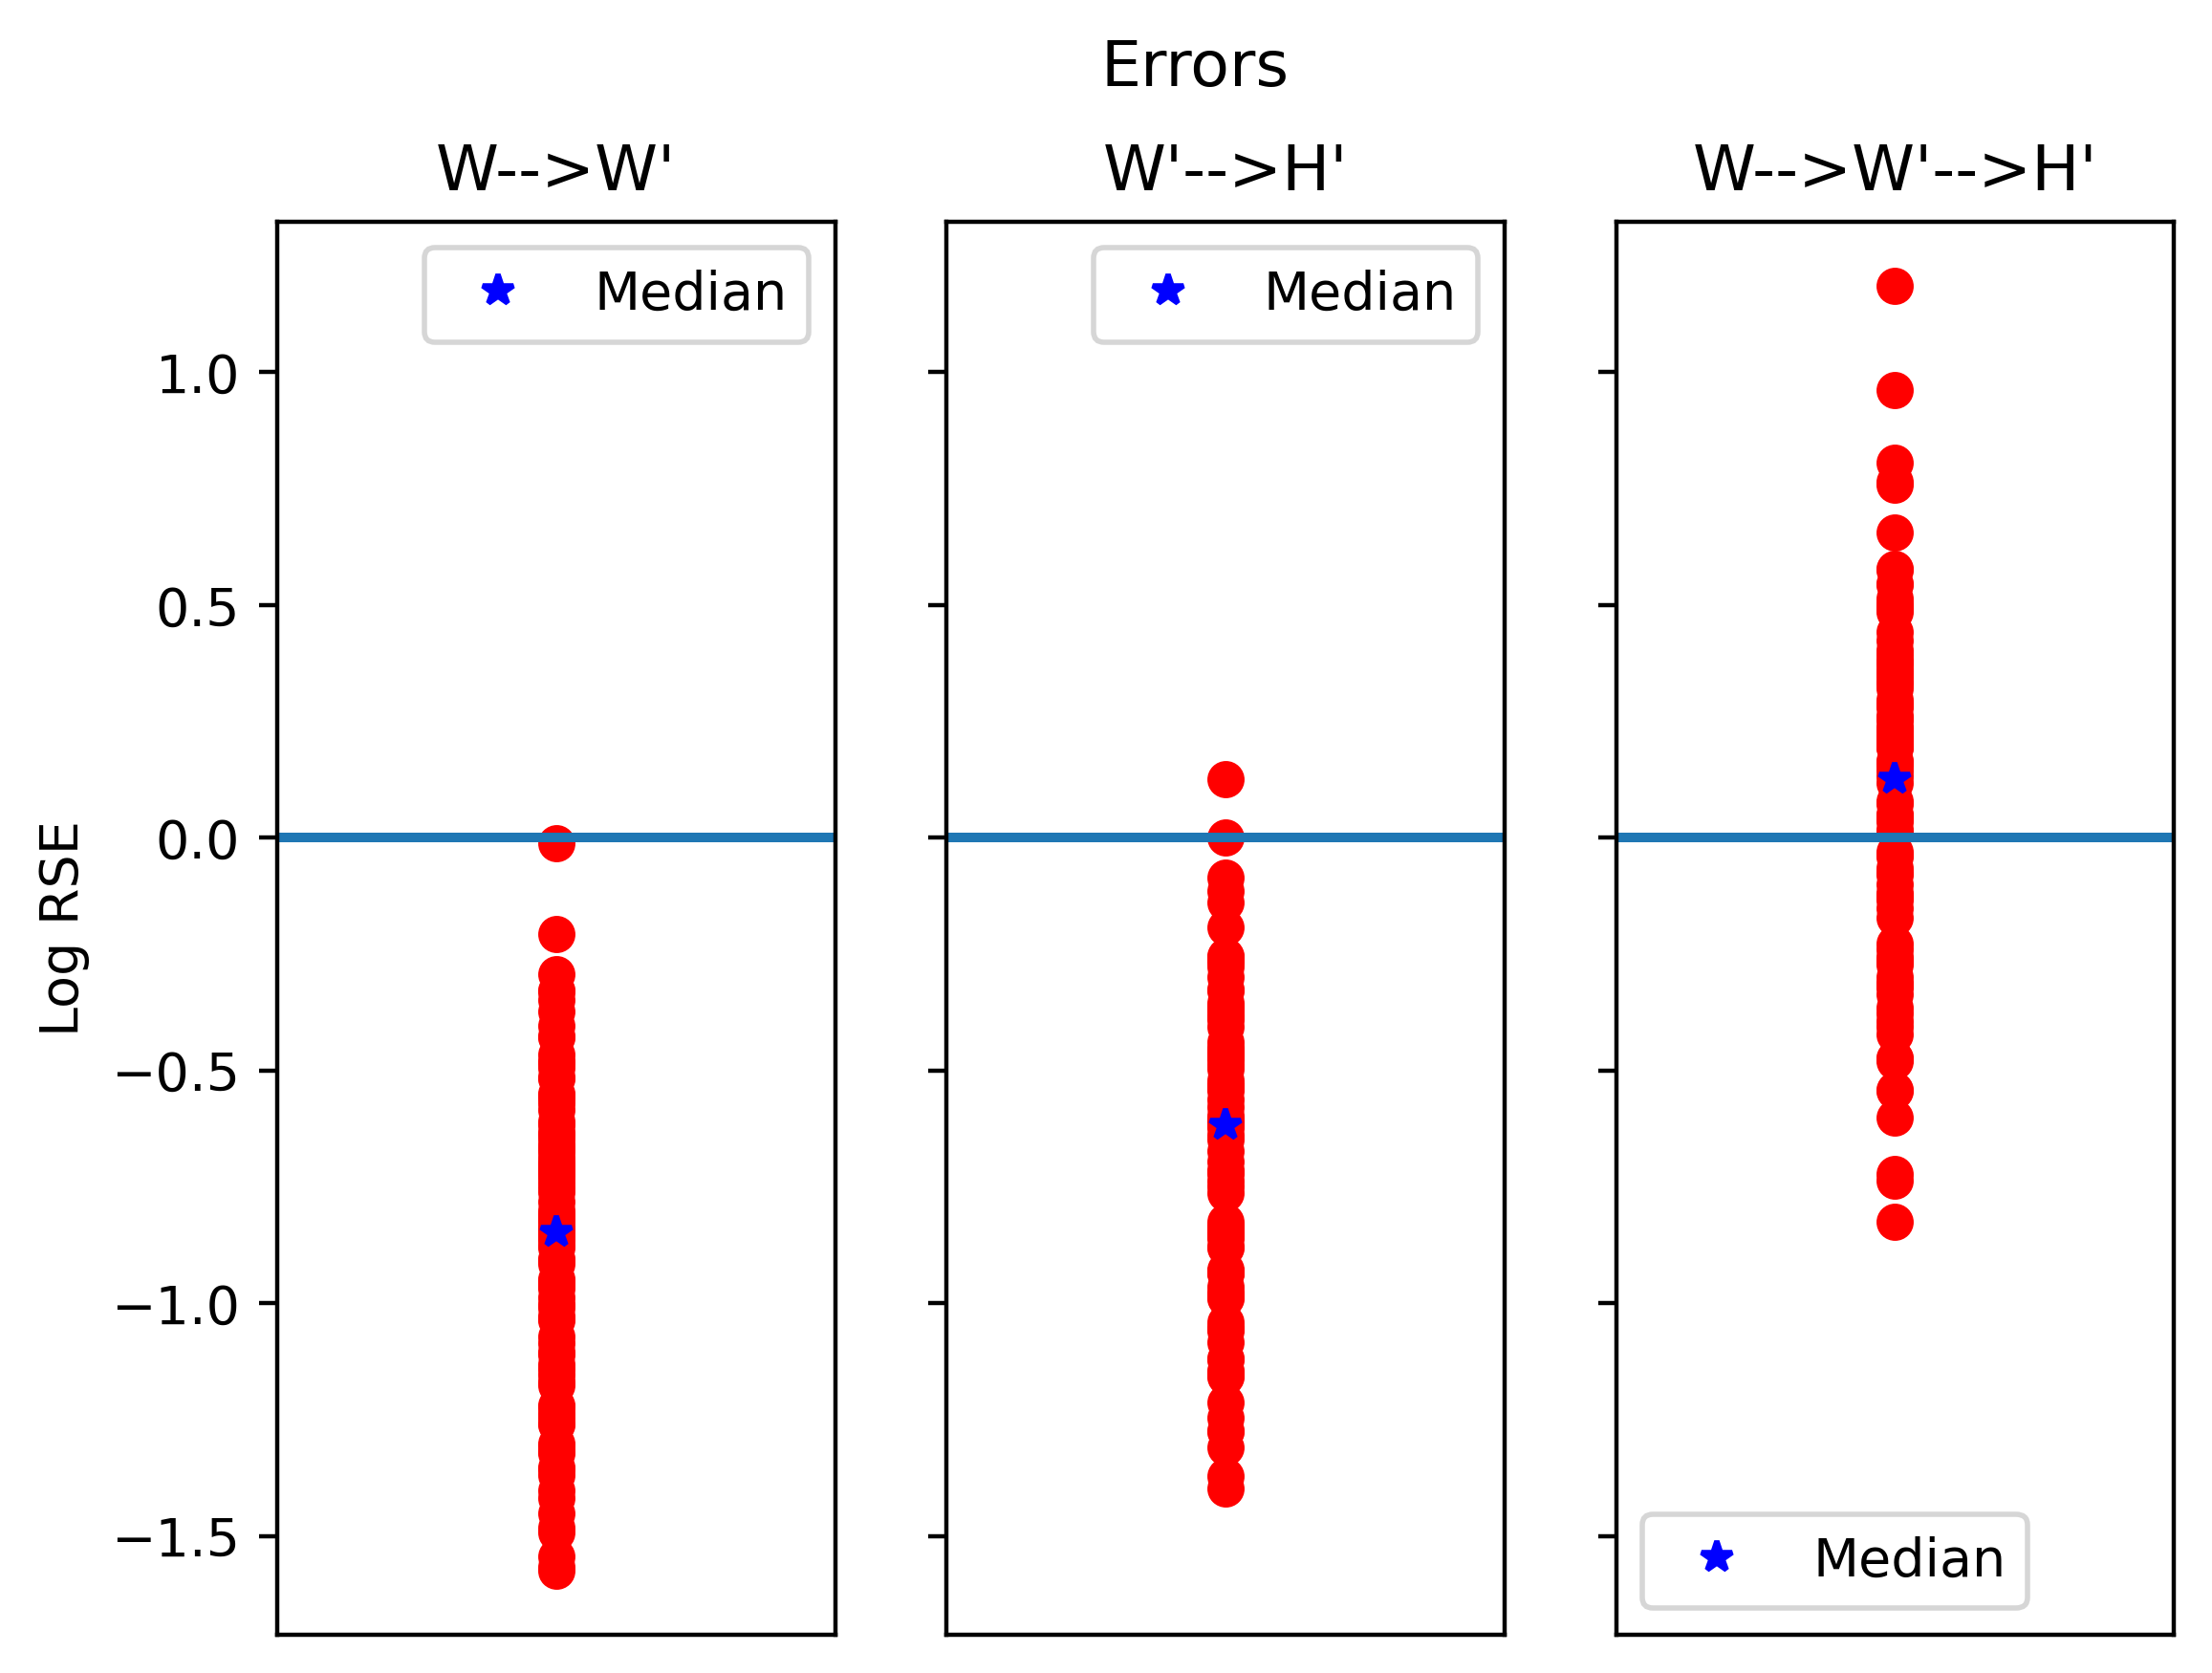

In [4]:
fig,ax = plt.subplots(1,3,sharex=True,sharey=True)
for rse_w,rse_ht,rse_hp in zip(RSEs_W,RSEs_H_from_true,RSEs_H_from_pred):
    ax[0].plot(0,np.log10(rse_w),'ro')
    ax[0].axhline(0)
    ax[0].set_xticks([])
    ax[0].set_ylabel("Log RSE")
    ax[0].set_title("W-->W'")
    ax[1].plot(0,np.log10(rse_ht),'ro')
    ax[1].axhline(0)
    ax[1].set_title("W'-->H'")
    ax[2].plot(0,np.log10(rse_hp),'ro')
    ax[2].axhline(0)
    ax[2].set_title("W-->W'-->H'")
fig.suptitle("Errors")
ax[0].plot(0,np.log10(np.median(RSEs_W)),'b*',label="Median")
ax[1].plot(0,np.log10(np.median(RSEs_H_from_true)),'b*',label="Median")
ax[2].plot(0,np.log10(np.median(RSEs_H_from_pred)),'b*',label="Median")
ax[0].legend()
ax[1].legend()
ax[2].legend()

**This is a confusing case to me, as it seems like both the dynamic error (W-->W') and the compression error (W'-->H') are low but when put together the error is high.** My guess right now is that maybe with so many modes (400 in this case) the system is not very robust to small errors.

**Overall though, I think hypothesis 2 is most likely.** In every case it appears that W' is predictable from W. There are likely issues arising from the compression of the SVD. For example, I have noticed that H' is no longer a (pseudo)Hankel matrix when reconstructed from W' (i.e. the skew-diagonals typically are not constant, shown below) which causes it to lose its meaning. **A better solution should replace the SVD with a different compression algorithm that enforces that the predicted H' is at least a Hankel matrix.** This could definitely be done by putting a loss on the difference between the elements of the skew diagonal.

In [34]:
np.set_printoptions(linewidth=10000000000000)
print(Hp_prediction_from_true)
print()
print(Hp_prediction_from_pred)

[[ 68659.04352701  58265.6151516   51411.28300053 ... -15054.91876002 -28720.30677279 -38025.7717657 ]
 [ 51986.74827022  45694.17705716  41754.09426311 ... -32208.15271757 -41501.38153369 -59369.3360918 ]
 [ 53443.98564409  48470.38359025  55650.66622015 ... -36047.03854731 -54692.49456322 -59010.67830571]
 ...
 [ 13766.49109188  12764.19555049  10455.07808503 ...   3153.12425183   2047.14828289   1576.61610933]
 [ 13667.81856486  11321.9820926    8577.45913412 ...   2700.736265     2117.30527443    299.86783029]
 [  8566.33611111   6266.01654223   5026.45290654 ...   2234.32078921    510.3208185     300.97075295]]

[[ 71329.12138131  68871.44909596  57991.36943738 ...   8315.82341473   1888.17012714  -9408.79830776]
 [ 64898.58798291  51574.15548581  44697.20471688 ...    669.89658716 -10542.15511466 -19307.46270268]
 [ 56802.44258229  53155.10626162  48145.34777947 ...  -8926.08196038 -17803.83996971 -33627.69520416]
 ...
 [ 12661.99434518  13817.23378298  12941.01310604 ...    811.